In [1]:
import json

# Librerías de terceros
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


In [2]:
df = pd.read_csv('../datasets/df_procesado.csv')
df.shape

(193050, 81)

In [3]:
# Separación de los datos en entrenamiento (80%) y validación (20%):

X = df.drop('loan_status', axis=1)
y = df['loan_status']

X_train, X_val, y_train, y_val = train_test_split(
       X, y, test_size=0.2, stratify=y, random_state=56
   )


In [4]:
print("Distribución de la variable respuesta en los datos de entrenamiento:")
print(y_train.value_counts(normalize=True))
print("\n")
print("Distribución de la variable respuesta en los datos de validación:")
print(y_val.value_counts(normalize=True))

Distribución de la variable respuesta en los datos de entrenamiento:
loan_status
0    0.766977
1    0.233023
Name: proportion, dtype: float64


Distribución de la variable respuesta en los datos de validación:
loan_status
0    0.766977
1    0.233023
Name: proportion, dtype: float64


In [5]:
# Selecciona GPU si está disponible, de lo contrario usa CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Muestra el dispositivo que se está utilizando
print(f"Usando: {device}")

Usando: cpu


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_val)

In [7]:
modelo = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo.fit(X_train_scaled, y_train)
print("\nModelo entrenado ✓")

/home/tomasgomez/Github/RedesNeuronales_Trabajo2/.venv/lib64/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



Modelo entrenado ✓


In [8]:
y_pred = modelo.predict(X_test_scaled)
y_prob = modelo.predict_proba(X_test_scaled)[:, 1]

In [9]:
print("\n── Classification Report ──────────────────────────────────")
print(classification_report(y_val, y_pred,
                             target_names=["No Default (0)", "Default (1)"]))
print(f"ROC-AUC: {roc_auc_score(y_val, y_prob):.4f}")


── Classification Report ──────────────────────────────────
                precision    recall  f1-score   support

No Default (0)       0.85      0.65      0.74     29613
   Default (1)       0.36      0.64      0.46      8997

      accuracy                           0.65     38610
     macro avg       0.60      0.64      0.60     38610
  weighted avg       0.74      0.65      0.67     38610

ROC-AUC: 0.6979


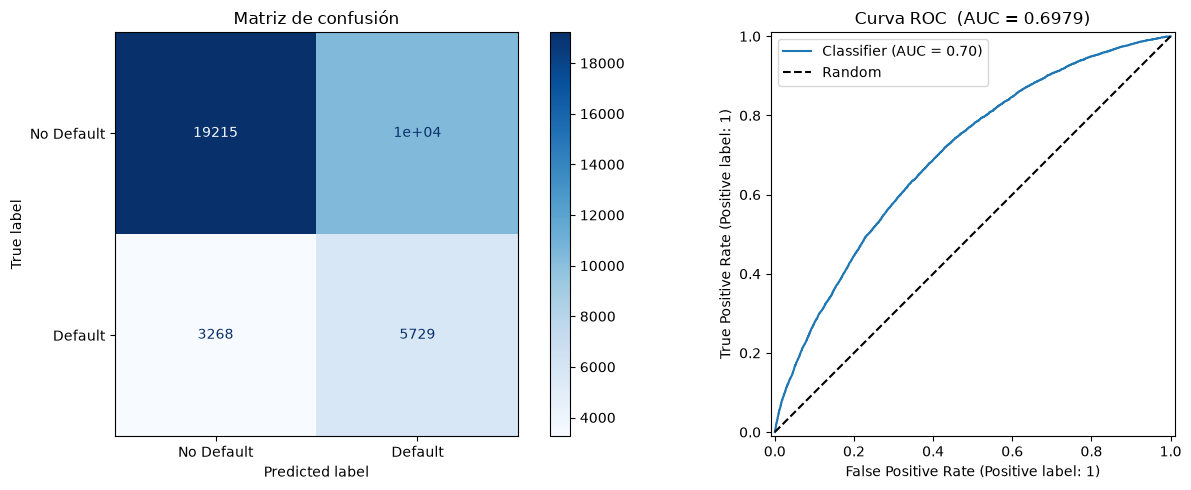

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Matriz de confusión")

# Curva ROC
RocCurveDisplay.from_predictions(y_val, y_prob, ax=axes[1])
axes[1].set_title(f"Curva ROC  (AUC = {roc_auc_score(y_val, y_prob):.4f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random")
axes[1].legend()

plt.tight_layout()
plt.show()


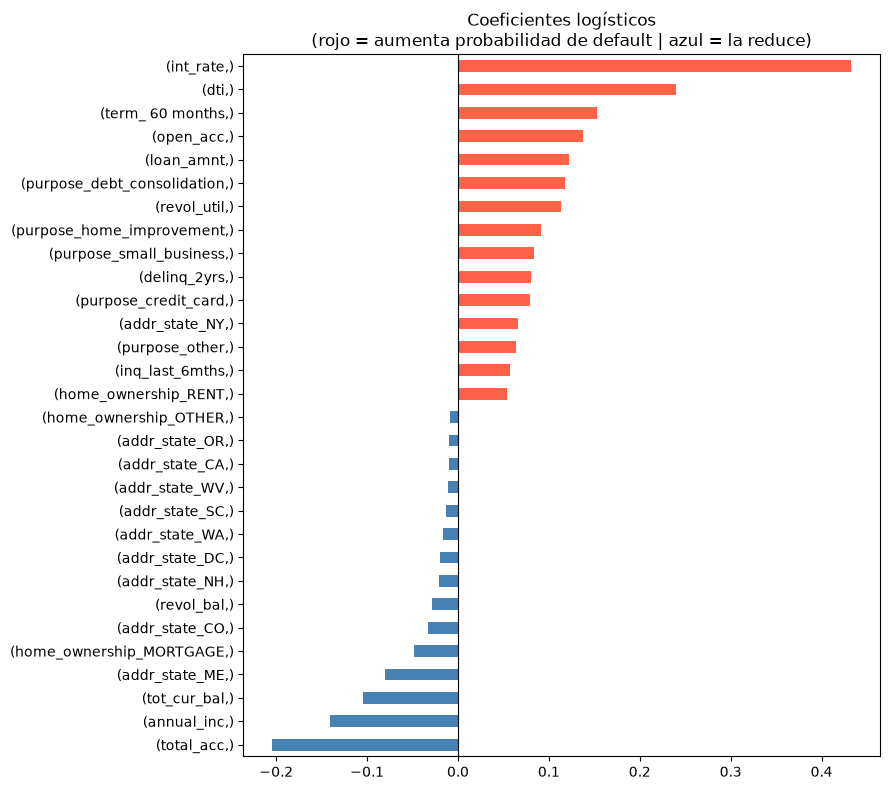


Top 10 variables que MÁS aumentan default:
int_rate                      0.432464
dti                           0.239585
term_ 60 months               0.152431
open_acc                      0.137648
loan_amnt                     0.122535
purpose_debt_consolidation    0.117902
revol_util                    0.112885
purpose_home_improvement      0.090907
purpose_small_business        0.083963
delinq_2yrs                   0.080325

Top 10 variables que MÁS reducen default:
addr_state_WA             -0.016898
addr_state_DC             -0.019735
addr_state_NH             -0.020310
revol_bal                 -0.028632
addr_state_CO             -0.033443
home_ownership_MORTGAGE   -0.048227
addr_state_ME             -0.080234
tot_cur_bal               -0.104734
annual_inc                -0.140655
total_acc                 -0.204139


In [11]:
coeficientes = pd.Series(
    modelo.coef_[0],
    index=[X_train.columns]
).sort_values(ascending=False)

# Top 15 positivos y negativos
top_n = 15
top_coefs = pd.concat([
    coeficientes.head(top_n),
    coeficientes.tail(top_n)
]).sort_values()

colores = ["steelblue" if v < 0 else "tomato" for v in top_coefs]

top_coefs.plot(kind="barh", figsize=(9, 8), color=colores)
plt.title("Coeficientes logísticos\n"
          "(rojo = aumenta probabilidad de default | "
          "azul = la reduce)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

print("\nTop 10 variables que MÁS aumentan default:")
print(coeficientes.head(10).to_string())

print("\nTop 10 variables que MÁS reducen default:")
print(coeficientes.tail(10).to_string())
